# Lab 03-06 · Random Processes Preview: Noise

Companion to chapter [03-06](../../chapters/03-06-random-processes-preview.md). Handout: [README.md](README.md). The ngspice netlist [rc_noise.cir](rc_noise.cir) confirms Example 03-06.4; run it with `python tools/run_spice.py 03-06` from the repository root.

Each part simulates noise as a random process and checks the chapter's formulas. Cells marked **🔮 Predict** ask for a prediction *before* running. The seed is fixed.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(2026)
k, q = 1.380649e-23, 1.602176634e-19

def gauss_markov(n, rho, sigma=1.0, paths=None):
    # exponentially correlated (RC-filtered) Gaussian noise, unit variance by default
    shape = (n,) if paths is None else (paths, n)
    w = rng.standard_normal(shape) * sigma * math.sqrt(1 - rho**2)
    x = np.empty(shape)
    x[..., 0] = sigma * rng.standard_normal(() if paths is None else paths)
    for i in range(1, n):
        x[..., i] = rho * x[..., i - 1] + w[..., i]
    return x

## Part 1 — Ensemble averages and time averages

**🔮 Predict:** for the offset population of Example 03-06.2, what does a long time average on one unit converge to? What does the ensemble average converge to?

In [2]:
t = np.linspace(0, 1e-6, 1001)                     # one period of a 1 MHz sinusoid
theta = rng.uniform(0, 2 * np.pi, 5000)
X = 2 * np.cos(2 * np.pi * 1e6 * t[None, :] + theta[:, None])
print(f"random-phase sinusoid: ensemble mean at t=0: {X[:, 0].mean():.4f}; ensemble power {np.mean(X[:, 0]**2):.4f} V^2")
print(f"time-averaged power of three single waveforms: {[round(float(np.mean(X[i, :-1]**2)), 4) for i in range(3)]} (theory 2)")

offsets = rng.normal(0, 1.0, 2000)                 # mV, one per unit
noise = rng.normal(0, 0.1, (2000, 5000))           # mV, white measurement noise
Y = offsets[:, None] + noise
print(f"offset population: ensemble mean {Y[:, 0].mean():.4f} mV, ensemble power {np.mean(Y[:, 0]**2):.4f} mV^2 (theory 1.01)")
print(f"unit 0: offset {offsets[0]:.4f} mV, its time average {Y[0].mean():.4f} mV")
print(f"fraction of units whose time average is beyond +/-2 mV: {np.mean(np.abs(Y.mean(axis=1)) > 2):.4f} (theory 2Q(2) = {2 * stats.norm.sf(2):.4f})")

random-phase sinusoid: ensemble mean at t=0: -0.0256; ensemble power 1.9808 V^2
time-averaged power of three single waveforms: [2.0, 2.0, 2.0] (theory 2)
offset population: ensemble mean 0.0274 mV, ensemble power 1.0415 mV^2 (theory 1.01)
unit 0: offset 1.3437 mV, its time average 1.3427 mV
fraction of units whose time average is beyond +/-2 mV: 0.0425 (theory 2Q(2) = 0.0455)


## Part 2 — Autocorrelation and power spectral density

Generate exponentially correlated noise with $\tau_c$ = 1 ms, sampled at 100 kHz, estimate its autocorrelation and its one-sided PSD (Welch's method averages many periodograms), and compare with $e^{-|\tau|/\tau_c}$ and the Lorentzian.

**🔮 Predict:** the PSD's corner frequency.

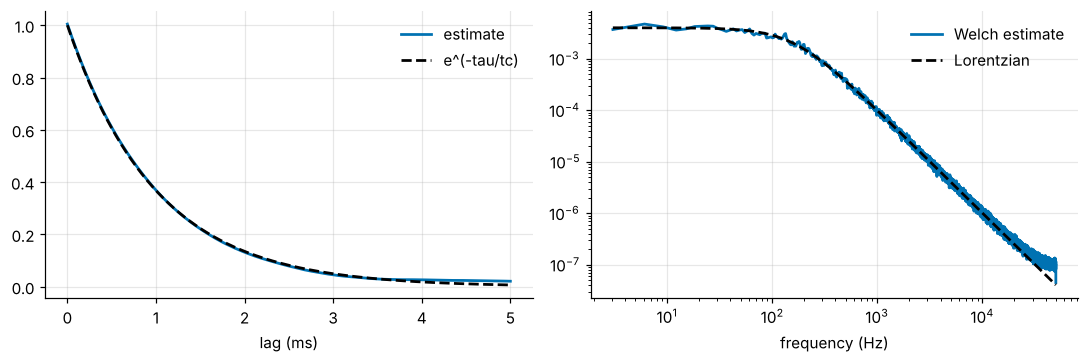

R(1 ms) estimate 0.3692 (theory e^-1 = 0.3679); corner frequency 159.2 Hz
area under the PSD 0.9936 (theory: total power 1)


In [3]:
fs, tc = 1e5, 1e-3
rho = math.exp(-1 / (fs * tc))
x = gauss_markov(2_000_000, rho)
lags = np.arange(0, 501)
r = np.array([np.mean(x[:x.size - L] * x[L:]) for L in lags])
f, G = signal.welch(x, fs=fs, nperseg=2**15)       # one-sided PSD, units 1/Hz for unit variance
G_th = 4 * tc / (1 + (2 * np.pi * f * tc)**2)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(lags / fs * 1e3, r, label="estimate"); ax[0].plot(lags / fs * 1e3, np.exp(-lags / (fs * tc)), "k--", label="e^(-tau/tc)")
ax[0].set_xlabel("lag (ms)"); ax[0].legend()
ax[1].loglog(f[1:], G[1:], label="Welch estimate"); ax[1].loglog(f[1:], G_th[1:], "k--", label="Lorentzian")
ax[1].set_xlabel("frequency (Hz)"); ax[1].legend(); fig.tight_layout(); plt.show()
print(f"R(1 ms) estimate {r[100]:.4f} (theory e^-1 = {math.exp(-1):.4f}); corner frequency {1 / (2 * math.pi * tc):.1f} Hz")
print(f"area under the PSD {np.trapezoid(G, f):.4f} (theory: total power 1)")

The Welch estimate follows the Lorentzian until the sampling rate's own effects appear near $f_s/2$. Its area is the total power, as Wiener–Khinchin promises.

## Part 3 — kT/C from a resistor's 4kTR

Simulate the RC circuit of Example 03-06.4 directly: a resistor's thermal noise current (one-sided density $4kT/R$) charges a 10 pF capacitor through 10 kΩ. Integrate the circuit equation with a small time step and measure the capacitor voltage's variance.

**🔮 Predict:** the rms voltage, and how it changes if R becomes 100 kΩ.

In [4]:
T, C = 300.0, 10e-12
for R in (10e3, 100e3):
    tau = R * C
    dt = tau / 100
    n = 400_000
    i_sd = math.sqrt(4 * k * T / R / (2 * dt))     # sample std of white current with one-sided density 4kT/R
    i = i_sd * rng.standard_normal(n)
    v = np.empty(n); v[0] = 0.0
    a = math.exp(-dt / tau)
    for m in range(1, n):                          # exact step response of the RC to a piecewise-constant current
        v[m] = a * v[m - 1] + (1 - a) * R * i[m]
    vr = math.sqrt(np.mean(v[n // 10:]**2))
    print(f"R = {R / 1e3:5.0f} kOhm: simulated rms {vr * 1e6:.2f} uV, sqrt(kT/C) = {math.sqrt(k * T / C) * 1e6:.2f} uV")

R =    10 kOhm: simulated rms 20.51 uV, sqrt(kT/C) = 20.35 uV


R =   100 kOhm: simulated rms 20.40 uV, sqrt(kT/C) = 20.35 uV


The resistor value drops out, as equipartition requires. The small residual difference comes from representing white noise with a finite time step.

## Part 4 — Shot noise from Poisson arrivals

Count electrons crossing a junction in 1 ns bins at an average current of 1 nA and measure the variance of the binned current.

In [5]:
I, dt = 1e-9, 1e-9
counts = rng.poisson(I / q * dt, 2_000_000)
i_bin = counts * q / dt
var_meas = i_bin.var()
var_theory = 2 * q * I * (1 / (2 * dt))            # one-sided density 2qI times noise bandwidth 1/(2 dt)
print(f"mean current {i_bin.mean() * 1e9:.4f} nA; variance {var_meas:.4e} A^2, theory 2qI/(2dt) = {var_theory:.4e} A^2")
print(f"mean electrons per bin {counts.mean():.3f}: the count's variance {counts.var():.3f} equals its mean (Poisson)")

mean current 1.0001 nA; variance 1.6048e-19 A^2, theory 2qI/(2dt) = 1.6022e-19 A^2
mean electrons per bin 6.242: the count's variance 6.252 equals its mean (Poisson)


## Part 5 — How much does averaging help?

Average exponentially correlated noise (σ = 1, $\tau_c$ = 1 ms) over records of length $T$, sampled at two different rates.

**🔮 Predict:** does sampling ten times faster reduce the scatter of a 100 ms average?

In [6]:
for fs in (1e4, 1e5):
    rho = math.exp(-1 / (fs * tc))
    for T in (0.01, 0.1):
        n = int(T * fs)
        means = gauss_markov(n, rho, paths=400).mean(axis=1)
        print(f"fs = {fs:7.0f} Hz, T = {T:5.2f} s: sd of average {means.std():.4f}; "
              f"sqrt(2 tc/T) = {math.sqrt(2 * tc / T):.4f}; naive 1/sqrt(n) = {1 / math.sqrt(n):.4f}")

fs =   10000 Hz, T =  0.01 s: sd of average 0.4382; sqrt(2 tc/T) = 0.4472; naive 1/sqrt(n) = 0.1000
fs =   10000 Hz, T =  0.10 s: sd of average 0.1385; sqrt(2 tc/T) = 0.1414; naive 1/sqrt(n) = 0.0316
fs =  100000 Hz, T =  0.01 s: sd of average 0.4401; sqrt(2 tc/T) = 0.4472; naive 1/sqrt(n) = 0.0316


fs =  100000 Hz, T =  0.10 s: sd of average 0.1404; sqrt(2 tc/T) = 0.1414; naive 1/sqrt(n) = 0.0100


The scatter tracks $\sqrt{2\tau_c/T}$, set by the record length, not the sample count. (At $T = 10\tau_c$ the exact formula of Example 03-06.6 is about 5% below the approximation.)

## Part 6 — 1/f noise and random walks

Synthesize 1/f noise by shaping white noise in the frequency domain, and a random walk by summing white noise. Watch how their averages behave as the averaging window grows.

In [7]:
N = 2**20
spec = np.fft.rfft(rng.standard_normal(N))
fr = np.fft.rfftfreq(N)
spec[1:] /= np.sqrt(fr[1:]); spec[0] = 0          # amplitude ~ 1/sqrt(f): power ~ 1/f
flicker = np.fft.irfft(spec, N); flicker /= flicker.std()
white = rng.standard_normal(N)
print("window   sd of window means: white    1/f")
for w in (16, 256, 4096, 65536):
    mw = white[: N // w * w].reshape(-1, w).mean(axis=1).std()
    mf = flicker[: N // w * w].reshape(-1, w).mean(axis=1).std()
    print(f"{w:6d}   {mw:.4f}   {mf:.4f}")
walks = np.cumsum(rng.standard_normal((2000, 4000)), axis=1)
for n in (100, 400, 1600):
    print(f"random walk after {n:4d} steps: ensemble sd {walks[:, n - 1].std():.2f} (theory sqrt(n) = {math.sqrt(n):.0f})")

window   sd of window means: white    1/f
    16   0.2508   0.9017
   256   0.0631   0.8001
  4096   0.0163   0.6868
 65536   0.0038   0.5366


random walk after  100 steps: ensemble sd 9.96 (theory sqrt(n) = 10)
random walk after  400 steps: ensemble sd 20.11 (theory sqrt(n) = 20)
random walk after 1600 steps: ensemble sd 39.51 (theory sqrt(n) = 40)


White-noise window means shrink by 4 for every 16-fold longer window ($1/\sqrt n$); the 1/f window means shrink only slowly, because longer windows reach lower frequencies where 1/f noise has more power. The random walk's spread grows as $\sqrt n$ without limit.

## Your turn

1. Repeat Part 3 with R = 1 MΩ and the circuit cooled to 77 K (liquid nitrogen). By what factor does the rms voltage on the capacitor fall, and does the resistor value matter?
2. In Part 6, average the 1/f noise with a window of 65,536 samples but subtract each window's linear trend first. Does detrending help, and what does that tell you about drift?